# 03 Model B: hERG block

Train the model that answers condition 3 of the screen: does this drug block the hERG potassium channel? It learns from the TDC `hERG` set, which is only a few hundred compounds.

The target is ROC-AUC >= 0.85. Because the set is so small, a single random holdout gives a number that swings with the seed, so this notebook cross validates and reports the **spread** as well as the mean. A scaffold split is run as the harder test on top of that.

Model B is only a fallback. For drugs on the CredibleMeds QT list the clinical listing is used instead, so Model B is reached only for CYP3A4 substrates that are not on that list.

In [7]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join("..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

import features
import models

PROCESSED_DIR = os.path.join("..", "data", "processed")

## Load, and make the sample size visible

In [8]:
X = np.load(os.path.join(PROCESSED_DIR, "X_herg.npy"))
y = np.load(os.path.join(PROCESSED_DIR, "y_herg.npy"))
herg_df = pd.read_csv(os.path.join(PROCESSED_DIR, "herg_clean.csv"))

print("X:", X.shape)
print("label counts:", np.bincount(y.astype(int)))
print("positive fraction:", round(float(y.mean()), 3))
print()
print(f"{X.shape[0]} compounds is small. One 20% holdout is only "
      f"{int(X.shape[0] * 0.2)} test molecules, which is why the number below")
print("is a cross validated mean with a standard deviation attached.")

X: (655, 2058)
label counts: [204 451]
positive fraction: 0.689

655 compounds is small. One 20% holdout is only 131 test molecules, which is why the number below
is a cross validated mean with a standard deviation attached.


## Cross validation

Five stratified folds. The standard deviation is reported because on a set this
size the mean on its own looks far more solid than it is.

In [9]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_aucs = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    model = models.train_rf(X[train_idx], y[train_idx])
    fold_auc = models.get_auc(model, X[test_idx], y[test_idx])
    fold_aucs.append(fold_auc)
    print(f"  fold {fold}: ROC-AUC {fold_auc:.4f}  "
          f"(train {len(train_idx)}, test {len(test_idx)})")

fold_aucs = np.array(fold_aucs)
mean_auc, std_auc = fold_aucs.mean(), fold_aucs.std()
print()
print(f"cross validated ROC-AUC: {mean_auc:.4f} +/- {std_auc:.4f}")
print(f"fold range: {fold_aucs.min():.4f} to {fold_aucs.max():.4f}")
print(f"target >= 0.85 -> {'MET' if mean_auc >= 0.85 else 'NOT MET'}")

  fold 1: ROC-AUC 0.8750  (train 524, test 131)
  fold 2: ROC-AUC 0.8951  (train 524, test 131)
  fold 3: ROC-AUC 0.8407  (train 524, test 131)
  fold 4: ROC-AUC 0.8821  (train 524, test 131)
  fold 5: ROC-AUC 0.9062  (train 524, test 131)

cross validated ROC-AUC: 0.8798 +/- 0.0223
fold range: 0.8407 to 0.9062
target >= 0.85 -> MET


## Scaffold split, the harder test

Whole scaffold groups go to one side only. A big drop against the cross
validated number means the model is recognising analogues rather than chemistry.

In [10]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from collections import defaultdict
from sklearn.metrics import roc_auc_score

def scaffold_split_indices(smiles_list, test_fraction=0.2):
    groups = defaultdict(list)
    for i, smi in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            groups[f"__unparsed_{i}"].append(i)
            continue
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
        groups[scaffold].append(i)
    ordered = sorted(groups.values(), key=len, reverse=True)
    n_test_target = int(len(smiles_list) * test_fraction)
    test_idx, train_idx = [], []
    for group in ordered:
        if len(test_idx) < n_test_target:
            test_idx.extend(group)
        else:
            train_idx.extend(group)
    return np.array(train_idx), np.array(test_idx), len(groups)

smiles = herg_df["Drug"].tolist()
sc_train, sc_test, n_scaffolds = scaffold_split_indices(smiles)
print(f"{n_scaffolds} distinct scaffolds over {len(smiles)} compounds")

model_sc = models.train_rf(X[sc_train], y[sc_train])
sc_auc = roc_auc_score(y[sc_test], model_sc.predict_proba(X[sc_test])[:, 1])

print()
print(f"cross validated ROC-AUC: {mean_auc:.4f} +/- {std_auc:.4f}")
print(f"scaffold split ROC-AUC:  {sc_auc:.4f}")
print(f"drop: {mean_auc - sc_auc:.4f}")

393 distinct scaffolds over 655 compounds

cross validated ROC-AUC: 0.8798 +/- 0.0223
scaffold split ROC-AUC:  0.9035
drop: -0.0237


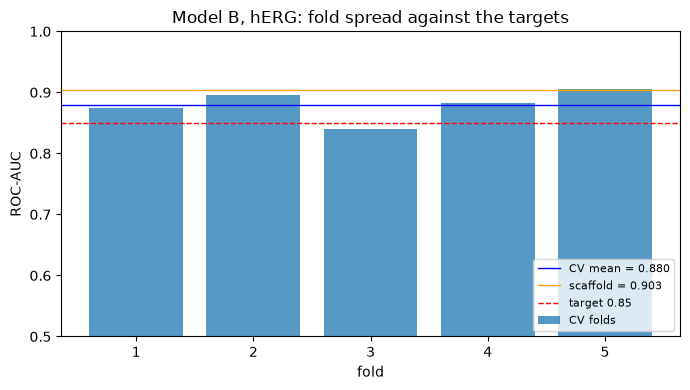

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 6), fold_aucs, alpha=0.75, label="CV folds")
ax.axhline(mean_auc, color="blue", linestyle="-", linewidth=1,
           label=f"CV mean = {mean_auc:.3f}")
ax.axhline(sc_auc, color="orange", linestyle="-", linewidth=1,
           label=f"scaffold = {sc_auc:.3f}")
ax.axhline(0.85, color="red", linestyle="--", linewidth=1, label="target 0.85")
ax.set_xlabel("fold")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.5, 1.0)
ax.set_title("Model B, hERG: fold spread against the targets")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## Final model

Validation is settled, so the model that ships is fitted on **all** the data.
Its performance is the cross validated number above, not a fresh score on the
rows it has now seen.

In [12]:
model_b = models.train_rf(X, y)
joblib.dump(model_b, os.path.join(PROCESSED_DIR, "model_b.joblib"))

metrics = {
    "model": "B (hERG)",
    "n_compounds": int(X.shape[0]),
    "positive_fraction": float(y.mean()),
    "roc_auc_cv_mean": float(mean_auc),
    "roc_auc_cv_std": float(std_auc),
    "roc_auc_scaffold": float(sc_auc),
    "n_folds": 5,
}
pd.Series(metrics).to_csv(os.path.join(PROCESSED_DIR, "metrics_model_b.csv"))
print("saved model_b.joblib and metrics_model_b.csv")
print()
for k, v in metrics.items():
    print(f"  {k}: {v}")

saved model_b.joblib and metrics_model_b.csv

  model: B (hERG)
  n_compounds: 655
  positive_fraction: 0.6885496183206107
  roc_auc_cv_mean: 0.8798238482384825
  roc_auc_cv_std: 0.022336295882764076
  roc_auc_scaffold: 0.9034878165312947
  n_folds: 5
